Customer Transaction Prediction

Step 1: Project Introduction

1.1 Project Title

Customer Transaction Prediction Using Machine Learning

1.2 Domain

In [ ]:
Banking

1.3 Problem Statement

The objective of this project is to develop a machine learning classification model that predicts whether a customer will make a transaction in the future, irrespective of the transaction amount.

1.4 Project Objectives

Understand and analyze the given dataset.

Perform data preprocessing and data cleaning.

Identify important patterns in the dataset.

Build multiple machine learning classification models.

Compare model performances using evaluation metrics.

Select the best-performing model for production.

Document challenges faced and solutions implemented.

Step 2: Environment Setup

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


2.2 Check Library Versions`

In [2]:
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

Pandas Version: 2.3.3
NumPy Version: 2.3.5


In [3]:
import os

os.chdir("E:/")

print("Current Working Directory:", os.getcwd())

Current Working Directory: E:\


In [4]:
os.makedirs("E:/Customer_Transaction_Prediction", exist_ok=True)

os.chdir("E:/Customer_Transaction_Prediction")

print("Project Directory:", os.getcwd())

Project Directory: E:\Customer_Transaction_Prediction


Step 3 – Load Dataset

3.1 Import and Load Excel File

In [12]:
import os

folder_path = r"E:\Customer_Transaction_Prediction"

print("Folder exists:", os.path.exists(folder_path))

if os.path.exists(folder_path):
    print("Folder contents:", os.listdir(folder_path))

Folder exists: True
Folder contents: ['PRCP-1003-CustTransPred (1)']


Step 3.2 – Load Dataset

In [13]:
import os
import pandas as pd

folder_path = r"E:\Customer_Transaction_Prediction\PRCP-1003-CustTransPred (1)"

print("Files:", os.listdir(folder_path))

Files: ['Data']


Step 3.3 – Identify Dataset

In [14]:
import os

folder_path = r"E:\Customer_Transaction_Prediction\PRCP-1003-CustTransPred (1)\Data"

print("Dataset files:", os.listdir(folder_path))

Dataset files: ['train(1).csv']


Step 3.4 – Load Dataset

In [15]:
import pandas as pd

file_path = r"E:\Customer_Transaction_Prediction\PRCP-1003-CustTransPred (1)\Data\train(1).csv"

df = pd.read_csv(file_path)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully!
Dataset Shape: (200000, 202)


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,var_23,var_24,var_25,var_26,var_27,var_28,var_29,var_30,var_31,var_32,var_33,var_34,var_35,var_36,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49,var_50,var_51,var_52,var_53,var_54,var_55,var_56,var_57,var_58,var_59,var_60,var_61,var_62,var_63,var_64,var_65,var_66,var_67,var_68,var_69,var_70,var_71,var_72,var_73,var_74,var_75,var_76,var_77,var_78,var_79,var_80,var_81,var_82,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_90,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100,var_101,var_102,var_103,var_104,var_105,var_106,var_107,var_108,var_109,var_110,var_111,var_112,var_113,var_114,var_115,var_116,var_117,var_118,var_119,var_120,var_121,var_122,var_123,var_124,var_125,var_126,var_127,var_128,var_129,var_130,var_131,var_132,var_133,var_134,var_135,var_136,var_137,var_138,var_139,var_140,var_141,var_142,var_143,var_144,var_145,var_146,var_147,var_148,var_149,var_150,var_151,var_152,var_153,var_154,var_155,var_156,var_157,var_158,var_159,var_160,var_161,var_162,var_163,var_164,var_165,var_166,var_167,var_168,var_169,var_170,var_171,var_172,var_173,var_174,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,-4.9200,5.7470,2.9252,3.1821,14.0137,0.5745,8.7989,14.5691,5.7487,-7.2393,4.2840,30.7133,10.5350,16.2191,2.5791,2.4716,14.3831,13.4325,-5.1488,-0.4073,4.9306,5.9965,-0.3085,12.9041,-3.8766,16.8911,11.1920,10.5785,0.6764,7.8871,4.6667,3.8743,-5.2387,7.3746,11.5767,12.0446,11.6418,-7.0170,5.9226,-14.2136,16.0283,5.3253,12.9194,29.0460,-0.6940,5.1736,-0.7474,14.8322,11.2668,5.3822,2.0183,10.1166,16.1828,4.9590,2.0771,-0.2154,8.6748,9.5319,5.8056,22.4321,5.0109,-4.7010,21.6374,0.5663,5.1999,8.8600,43.1127,18.3816,-2.3440,23.4104,6.5199,12.1983,13.6468,13.8372,1.3675,2.9423,-4.5213,21.4669,9.3225,16.4597,7.9984,-1.7069,-21.4494,6.7806,11.0924,9.9913,14.8421,0.1812,8.9642,16.2572,2.1743,-3.4132,9.4763,13.3102,26.5376,1.4403,14.7100,6.0454,9.5426,17.1554,14.1104,24.3627,2.0323,6.7602,3.9141,-0.4851,2.5240,1.5093,2.5516,15.5752,-13.4221,7.2739,16.0094,9.7268,0.8897,0.7754,4.2218,12.0039,13.8571,-0.7338,-1.9245,15.4462,12.8287,0.3587,9.6508,6.5674,5.1726,3.1345,29.4547,31.4045,2.8279,15.6599,8.3307,-5.6011,19.0614,11.2663,8.6989,8.3694,11.5659,-16.4727,4.0288,17.9244,18.5177,10.7800,9.0056,16.6964,10.4838,1.6573,12.1749,-13.1324,17.6054,11.5423,15.4576,5.3133,3.6159,5.0384,6.6760,12.6644,2.7004,-0.6975,9.5981,5.4879,-4.7645,-8.4254,20.8773,3.1531,18.5618,7.7423,-10.1245,13.7241,-3.5189,1.7202,-8.4051,9.0164,3.0657,14.3691,25.8398,5.8764,11.8411,-19.7159,17.5743,0.5857,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,3.1468,8.0851,-0.4032,8.0585,14.0239,8.4135,5.4345,13.7003,13.8275,-15.5849,7.8000,28.5708,3.4287,2.7407,8.5524,3.3716,6.9779,13.8910,-11.7684,-2.5586,5.0464,0.5481,-9.2987,7.8755,1.2859,19.3710,11.3702,0.7399,2.7995,5.8434,10.8160,3.6783,-11.1147,1.8730,9.8775,11.7842,1.2444,-47.3797,7.3718,0.1948,34.4014,25.7037,11.8343,13.2256,-4.1083,6.6885,-8.0946,18.5995,19.3219,7.0118,1.9210,8.8682,8.0109,-7.2417,1.7944,-1.3147,8.1042,1.5365,5.4007,7.9344,5.0220,2.2302,40.5632,0.5134,3.1701,20.1068,7.7841,7.0529,3.2709,23.4822,5.5075,13.7814,2.5462,18.1782,0.3683,-4.8210,-5.4850,13.7867,-13.5901,11.0993,7.9022,12.2301,0.4768,6.8852,8.0905,10.9631,11.7569,-1.2722,24.7876,26.6881,1.8944,0.6939,-13.6950,8.4068,35.4734,1.7093,15.1866,2.6227,7.3412,32.0888,13.9550,13.0858,6.6203,7.1051,5.3523,8.5426,3.6159,4.1569,3.0454,7.8522,-11.5100,7.5109,31.5899,9.5018,8.2736,10.1633,0.1225,12.5942,14.5697

Step 4 – Initial Data Understanding

4.1 Check Dataset Shape

In [16]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 200000
Number of Columns: 202


4.2 Check First Five Records

In [17]:
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,var_23,var_24,var_25,var_26,var_27,var_28,var_29,var_30,var_31,var_32,var_33,var_34,var_35,var_36,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49,var_50,var_51,var_52,var_53,var_54,var_55,var_56,var_57,var_58,var_59,var_60,var_61,var_62,var_63,var_64,var_65,var_66,var_67,var_68,var_69,var_70,var_71,var_72,var_73,var_74,var_75,var_76,var_77,var_78,var_79,var_80,var_81,var_82,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_90,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100,var_101,var_102,var_103,var_104,var_105,var_106,var_107,var_108,var_109,var_110,var_111,var_112,var_113,var_114,var_115,var_116,var_117,var_118,var_119,var_120,var_121,var_122,var_123,var_124,var_125,var_126,var_127,var_128,var_129,var_130,var_131,var_132,var_133,var_134,var_135,var_136,var_137,var_138,var_139,var_140,var_141,var_142,var_143,var_144,var_145,var_146,var_147,var_148,var_149,var_150,var_151,var_152,var_153,var_154,var_155,var_156,var_157,var_158,var_159,var_160,var_161,var_162,var_163,var_164,var_165,var_166,var_167,var_168,var_169,var_170,var_171,var_172,var_173,var_174,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,-4.9200,5.7470,2.9252,3.1821,14.0137,0.5745,8.7989,14.5691,5.7487,-7.2393,4.2840,30.7133,10.5350,16.2191,2.5791,2.4716,14.3831,13.4325,-5.1488,-0.4073,4.9306,5.9965,-0.3085,12.9041,-3.8766,16.8911,11.1920,10.5785,0.6764,7.8871,4.6667,3.8743,-5.2387,7.3746,11.5767,12.0446,11.6418,-7.0170,5.9226,-14.2136,16.0283,5.3253,12.9194,29.0460,-0.6940,5.1736,-0.7474,14.8322,11.2668,5.3822,2.0183,10.1166,16.1828,4.9590,2.0771,-0.2154,8.6748,9.5319,5.8056,22.4321,5.0109,-4.7010,21.6374,0.5663,5.1999,8.8600,43.1127,18.3816,-2.3440,23.4104,6.5199,12.1983,13.6468,13.8372,1.3675,2.9423,-4.5213,21.4669,9.3225,16.4597,7.9984,-1.7069,-21.4494,6.7806,11.0924,9.9913,14.8421,0.1812,8.9642,16.2572,2.1743,-3.4132,9.4763,13.3102,26.5376,1.4403,14.7100,6.0454,9.5426,17.1554,14.1104,24.3627,2.0323,6.7602,3.9141,-0.4851,2.5240,1.5093,2.5516,15.5752,-13.4221,7.2739,16.0094,9.7268,0.8897,0.7754,4.2218,12.0039,13.8571,-0.7338,-1.9245,15.4462,12.8287,0.3587,9.6508,6.5674,5.1726,3.1345,29.4547,31.4045,2.8279,15.6599,8.3307,-5.6011,19.0614,11.2663,8.6989,8.3694,11.5659,-16.4727,4.0288,17.9244,18.5177,10.7800,9.0056,16.6964,10.4838,1.6573,12.1749,-13.1324,17.6054,11.5423,15.4576,5.3133,3.6159,5.0384,6.6760,12.6644,2.7004,-0.6975,9.5981,5.4879,-4.7645,-8.4254,20.8773,3.1531,18.5618,7.7423,-10.1245,13.7241,-3.5189,1.7202,-8.4051,9.0164,3.0657,14.3691,25.8398,5.8764,11.8411,-19.7159,17.5743,0.5857,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,3.1468,8.0851,-0.4032,8.0585,14.0239,8.4135,5.4345,13.7003,13.8275,-15.5849,7.8000,28.5708,3.4287,2.7407,8.5524,3.3716,6.9779,13.8910,-11.7684,-2.5586,5.0464,0.5481,-9.2987,7.8755,1.2859,19.3710,11.3702,0.7399,2.7995,5.8434,10.8160,3.6783,-11.1147,1.8730,9.8775,11.7842,1.2444,-47.3797,7.3718,0.1948,34.4014,25.7037,11.8343,13.2256,-4.1083,6.6885,-8.0946,18.5995,19.3219,7.0118,1.9210,8.8682,8.0109,-7.2417,1.7944,-1.3147,8.1042,1.5365,5.4007,7.9344,5.0220,2.2302,40.5632,0.5134,3.1701,20.1068,7.7841,7.0529,3.2709,23.4822,5.5075,13.7814,2.5462,18.1782,0.3683,-4.8210,-5.4850,13.7867,-13.5901,11.0993,7.9022,12.2301,0.4768,6.8852,8.0905,10.9631,11.7569,-1.2722,24.7876,26.6881,1.8944,0.6939,-13.6950,8.4068,35.4734,1.7093,15.1866,2.6227,7.3412,32.0888,13.9550,13.0858,6.6203,7.1051,5.3523,8.5426,3.6159,4.1569,3.0454,7.8522,-11.5100,7.5109,31.5899,9.5018,8.2736,10.1633,0.1225,12.5942,14.5697

4.3 Check Last Five Records

In [18]:
df.tail()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,var_23,var_24,var_25,var_26,var_27,var_28,var_29,var_30,var_31,var_32,var_33,var_34,var_35,var_36,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49,var_50,var_51,var_52,var_53,var_54,var_55,var_56,var_57,var_58,var_59,var_60,var_61,var_62,var_63,var_64,var_65,var_66,var_67,var_68,var_69,var_70,var_71,var_72,var_73,var_74,var_75,var_76,var_77,var_78,var_79,var_80,var_81,var_82,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_90,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100,var_101,var_102,var_103,var_104,var_105,var_106,var_107,var_108,var_109,var_110,var_111,var_112,var_113,var_114,var_115,var_116,var_117,var_118,var_119,var_120,var_121,var_122,var_123,var_124,var_125,var_126,var_127,var_128,var_129,var_130,var_131,var_132,var_133,var_134,var_135,var_136,var_137,var_138,var_139,var_140,var_141,var_142,var_143,var_144,var_145,var_146,var_147,var_148,var_149,var_150,var_151,var_152,var_153,var_154,var_155,var_156,var_157,var_158,var_159,var_160,var_161,var_162,var_163,var_164,var_165,var_166,var_167,var_168,var_169,var_170,var_171,var_172,var_173,var_174,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
199995,train_199995,0,11.4880,-0.4956,8.2622,3.5142,10.3404,11.6081,5.6709,15.1516,-0.6209,5.6669,3.7574,-9.5348,13.9860,5.2982,8.2705,14.1527,7.4540,-5.0105,12.0465,8.6349,9.9137,25.1376,1.0914,3.2326,7.7802,13.9939,2.9085,0.1005,4.2369,7.5665,-9.2149,9.5746,1.4012,7.4211,11.0075,7.8080,4.5567,4.9861,9.7471,0.0722,5.9053,8.1743,10.8800,11.1665,4.2600,-2.1296,8.7833,-15.5727,-8.4916,22.1905,12.4110,15.1168,1.6041,6.1868,10.9576,18.7371,15.2986,5.7322,5.1244,9.8225,14.0315,-23.6064,-1.3403,-2.5577,6.3582,-5.4557,5.6063,7.0054,5.0171,-5.0055,28.9502,1.2297,4.4918,19.5568,20.8357,19.2136,17.6422,17.9836,4.0395,14.0761,-5.7878,16.3870,-14.1721,-13.0269,-2.5955,21.4526,15.6163,0.9845,8.2110,-0.8553,-12.1682,6.7779,7.3895,10.5084,15.5057,-0.6812,5.8999,6.1825,3.1038,-1.6930,-18.8473,9.9358,25.3359,1.3647,11.8509,5.0357,6.4630,18.4008,14.3787,19.0369,-0.6364,6.9155,3.6763,3.1460,4.9442,-1.8289,1.3521,34.6265,-0.6869,-5.3781,20.5030,10.9614,4.9677,6.1408,2.2575,12.8757,14.2253,-1.2868,0.2212,16.8661,12.7663,1.2414,7.1304,7.4108,-6.3369,3.0760,24.9796,20.3410,5.3312,23.7116,2.4745,11.2013,17.8165,13.0057,9.5506,5.3589,13.2491,-3.3068,3.6998,2.5927,14.3025,8.1596,7.9609,18.3343,4.3086,1.3546,12.4158,-5.3985,16.3683,10.4522,35.4923,5.5477,7.4244,12.5459,-6.7840,31.1895,2.6529,-11.1867,9.8865,5.4730,-5.3880,-0.4698,24.4025,-5.4493,11.3529,7.7075,-5.0491,13.0756,15.8271,3.3580,-14.3371,10.4421,7.6530,9.4585,22.7783,-4.0305,4.2233,-6.3906,13.5058,-0.4594,6.1415,13.2305,3.9901,0.9388,18.0249,-1.7939,2.1661,8.5326,16.6660,-17.8661
199996,train_199996,0,4.9149,-2.4484,16.7052,6.6345,8.3096,-10.5628,5.8802,21.5940,-3.6797,6.0019,6.5576,-11.8776,14.4131,3.3087,3.5800,14.1597,7.5191,-8.8715,17.9467,17.0237,6.6459,18.2345,0.8982,2.2532,15.4977,13.3282,5.2281,-3.7424,5.5144,5.7148,-13.7470,7.4369,1.3041,12.7552,12.5362,-1.1002,2.4370,6.2631,14.8565,-2.9862,-7.8820,7.1320,11.8869,11.4218,8.9282,-27.2007,14.5962,-19.8502,26.0775,24.3915,12.6910,10.2453,6.8173,4.5666,-9.5685,18.4685,16.9534,7.3660,4.7038,9.4559,6.0037,-10.8728,0.7859,4.7000,7.8077,-1.7926,6.1534,12.9087,5.0398,-0.4247,22.6256,0.7166,0.6533,13.5821,20.3267,25.5380,14.0155,17.3326,4.2046,14.0195,11.4812,17.9954,-18.3549,-3.4537,1.1233,22.3135,1.9795,16.0239,4.7492,0.2446,-39.6406,6.9473,9.9392,11.1977,14.1006,-0.8012,18.8214,32.9827,1.7989,-0.2476,-15.5294,9.5501,11.8548,1.5127,11.3998,4.2304,6.6777,11.3434,14.2993,13.1205,13.3224,7.3143,3.6817,9.7780,4.0491,2.7221,4.4344,3.7648,2.1927,-2.9197,23.0679,12.2112,

4.4 Check Dataset Information

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


4.5 Check Column Names

In [20]:
print("Total Columns:", len(df.columns))
print("\nColumn Names:\n")
print(df.columns.tolist())

Total Columns: 202

Column Names:

['ID_code', 'target', 'var_0', 'var_1', 'var_2', 'var_3', 'var_4', 'var_5', 'var_6', 'var_7', 'var_8', 'var_9', 'var_10', 'var_11', 'var_12', 'var_13', 'var_14', 'var_15', 'var_16', 'var_17', 'var_18', 'var_19', 'var_20', 'var_21', 'var_22', 'var_23', 'var_24', 'var_25', 'var_26', 'var_27', 'var_28', 'var_29', 'var_30', 'var_31', 'var_32', 'var_33', 'var_34', 'var_35', 'var_36', 'var_37', 'var_38', 'var_39', 'var_40', 'var_41', 'var_42', 'var_43', 'var_44', 'var_45', 'var_46', 'var_47', 'var_48', 'var_49', 'var_50', 'var_51', 'var_52', 'var_53', 'var_54', 'var_55', 'var_56', 'var_57', 'var_58', 'var_59', 'var_60', 'var_61', 'var_62', 'var_63', 'var_64', 'var_65', 'var_66', 'var_67', 'var_68', 'var_69', 'var_70', 'var_71', 'var_72', 'var_73', 'var_74', 'var_75', 'var_76', 'var_77', 'var_78', 'var_79', 'var_80', 'var_81', 'var_82', 'var_83', 'var_84', 'var_85', 'var_86', 'var_87', 'var_88', 'var_89', 'var_90', 'var_91', 'var_92', 'var_93', 'var_94', 'va

Step 5 – Data Quality Checks

5.1 Check Missing Values

In [21]:
print("Total Missing Values:", df.isnull().sum().sum())

print("\nColumns with Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Total Missing Values: 0

Columns with Missing Values:
Series([], dtype: int64)


5.2 Check Duplicate Records

In [22]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


5.3 Check Duplicate Customer IDs

In [23]:
print("Duplicate Customer IDs:", df['ID_code'].duplicated().sum())

Duplicate Customer IDs: 0


5.4 Check Target Values

In [24]:
print("Target Unique Values:", df['target'].unique())

print("\nTarget Value Counts:")
print(df['target'].value_counts())

Target Unique Values: [0 1]

Target Value Counts:
target
0    179902
1     20098
Name: count, dtype: int64


Step 6 – Target Variable Analysis

6.1 Check Target Distribution

In [25]:
print("Target Distribution:")
print(df['target'].value_counts())

Target Distribution:
target
0    179902
1     20098
Name: count, dtype: int64


6.2 Calculate Target Percentage

In [26]:
target_percentage = df['target'].value_counts(normalize=True) * 100

print("Target Percentage:")
print(target_percentage)

Target Percentage:
target
0    89.951
1    10.049
Name: proportion, dtype: float64


6.3 Visualize Target Distribution

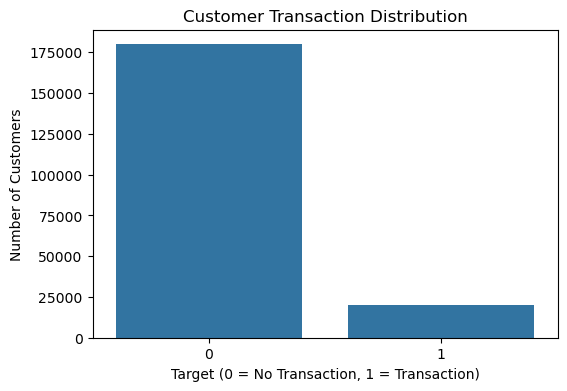

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='target')

plt.title("Customer Transaction Distribution")
plt.xlabel("Target (0 = No Transaction, 1 = Transaction)")
plt.ylabel("Number of Customers")

plt.show()

6.4 Analyze Class Imbalance

In [28]:
class_0 = (df['target'] == 0).sum()
class_1 = (df['target'] == 1).sum()

print("Customers without Transaction:", class_0)
print("Customers with Transaction:", class_1)

print("\nClass Imbalance Ratio:", round(class_0 / class_1, 2))

Customers without Transaction: 179902
Customers with Transaction: 20098

Class Imbalance Ratio: 8.95


Step 7 – Data Preprocessing

7.1 Separate Features and Target

In [29]:
X = df.drop(['ID_code', 'target'], axis=1)

y = df['target']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (200000, 200)
Target Shape: (200000,)


7.2 Check Feature Data Types

In [30]:
print(X.dtypes.value_counts())

float64    200
Name: count, dtype: int64


7.3 Check Missing Values in Features

In [31]:
print("Missing Values in Features:", X.isnull().sum().sum())

Missing Values in Features: 0


7.4 Check Target Data Type

In [32]:
print("Target Data Type:", y.dtype)
print("Target Classes:", y.unique())

Target Data Type: int64
Target Classes: [0 1]


7.5 Verify Prepared Data

In [33]:
print("Feature Dataset:")
display(X.head())

print("Target Dataset:")
display(y.head())

Feature Dataset:


,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,var_23,var_24,var_25,var_26,var_27,var_28,var_29,var_30,var_31,var_32,var_33,var_34,var_35,var_36,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49,var_50,var_51,var_52,var_53,var_54,var_55,var_56,var_57,var_58,var_59,var_60,var_61,var_62,var_63,var_64,var_65,var_66,var_67,var_68,var_69,var_70,var_71,var_72,var_73,var_74,var_75,var_76,var_77,var_78,var_79,var_80,var_81,var_82,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_90,var_91,var_92,var_93,var_94,var_95,var_96,var_97,var_98,var_99,var_100,var_101,var_102,var_103,var_104,var_105,var_106,var_107,var_108,var_109,var_110,var_111,var_112,var_113,var_114,var_115,var_116,var_117,var_118,var_119,var_120,var_121,var_122,var_123,var_124,var_125,var_126,var_127,var_128,var_129,var_130,var_131,var_132,var_133,var_134,var_135,var_136,var_137,var_138,var_139,var_140,var_141,var_142,var_143,var_144,var_145,var_146,var_147,var_148,var_149,var_150,var_151,var_152,var_153,var_154,var_155,var_156,var_157,var_158,var_159,var_160,var_161,var_162,var_163,var_164,var_165,var_166,var_167,var_168,var_169,var_170,var_171,var_172,var_173,var_174,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,-4.9200,5.7470,2.9252,3.1821,14.0137,0.5745,8.7989,14.5691,5.7487,-7.2393,4.2840,30.7133,10.5350,16.2191,2.5791,2.4716,14.3831,13.4325,-5.1488,-0.4073,4.9306,5.9965,-0.3085,12.9041,-3.8766,16.8911,11.1920,10.5785,0.6764,7.8871,4.6667,3.8743,-5.2387,7.3746,11.5767,12.0446,11.6418,-7.0170,5.9226,-14.2136,16.0283,5.3253,12.9194,29.0460,-0.6940,5.1736,-0.7474,14.8322,11.2668,5.3822,2.0183,10.1166,16.1828,4.9590,2.0771,-0.2154,8.6748,9.5319,5.8056,22.4321,5.0109,-4.7010,21.6374,0.5663,5.1999,8.8600,43.1127,18.3816,-2.3440,23.4104,6.5199,12.1983,13.6468,13.8372,1.3675,2.9423,-4.5213,21.4669,9.3225,16.4597,7.9984,-1.7069,-21.4494,6.7806,11.0924,9.9913,14.8421,0.1812,8.9642,16.2572,2.1743,-3.4132,9.4763,13.3102,26.5376,1.4403,14.7100,6.0454,9.5426,17.1554,14.1104,24.3627,2.0323,6.7602,3.9141,-0.4851,2.5240,1.5093,2.5516,15.5752,-13.4221,7.2739,16.0094,9.7268,0.8897,0.7754,4.2218,12.0039,13.8571,-0.7338,-1.9245,15.4462,12.8287,0.3587,9.6508,6.5674,5.1726,3.1345,29.4547,31.4045,2.8279,15.6599,8.3307,-5.6011,19.0614,11.2663,8.6989,8.3694,11.5659,-16.4727,4.0288,17.9244,18.5177,10.7800,9.0056,16.6964,10.4838,1.6573,12.1749,-13.1324,17.6054,11.5423,15.4576,5.3133,3.6159,5.0384,6.6760,12.6644,2.7004,-0.6975,9.5981,5.4879,-4.7645,-8.4254,20.8773,3.1531,18.5618,7.7423,-10.1245,13.7241,-3.5189,1.7202,-8.4051,9.0164,3.0657,14.3691,25.8398,5.8764,11.8411,-19.7159,17.5743,0.5857,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,3.1468,8.0851,-0.4032,8.0585,14.0239,8.4135,5.4345,13.7003,13.8275,-15.5849,7.8000,28.5708,3.4287,2.7407,8.5524,3.3716,6.9779,13.8910,-11.7684,-2.5586,5.0464,0.5481,-9.2987,7.8755,1.2859,19.3710,11.3702,0.7399,2.7995,5.8434,10.8160,3.6783,-11.1147,1.8730,9.8775,11.7842,1.2444,-47.3797,7.3718,0.1948,34.4014,25.7037,11.8343,13.2256,-4.1083,6.6885,-8.0946,18.5995,19.3219,7.0118,1.9210,8.8682,8.0109,-7.2417,1.7944,-1.3147,8.1042,1.5365,5.4007,7.9344,5.0220,2.2302,40.5632,0.5134,3.1701,20.1068,7.7841,7.0529,3.2709,23.4822,5.5075,13.7814,2.5462,18.1782,0.3683,-4.8210,-5.4850,13.7867,-13.5901,11.0993,7.9022,12.2301,0.4768,6.8852,8.0905,10.9631,11.7569,-1.2722,24.7876,26.6881,1.8944,0.6939,-13.6950,8.4068,35.4734,1.7093,15.1866,2.6227,7.3412,32.0888,13.9550,13.0858,6.6203,7.1051,5.3523,8.5426,3.6159,4.1569,3.0454,7.8522,-11.5100,7.5109,31.5899,9.5018,8.2736,10.1633,0.1225,12.5942,14.5697,2.4354,0.8194,16.5346,12.4205,-0.1

Target Dataset:


0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

Step 8 – Feature Analysis and Selection

8.1 Check Unique Values in Features

In [34]:
unique_values = X.nunique()

print("Total Features:", X.shape[1])
print("Constant Features:", (unique_values == 1).sum())

Total Features: 200
Constant Features: 0


8.2 Identify Constant Features

In [35]:
constant_features = unique_values[unique_values == 1].index.tolist()

print("Constant Features:", constant_features)

Constant Features: []


8.3 Remove Constant Features

In [36]:
X = X.drop(columns=constant_features)

print("Features Shape After Selection:", X.shape)

Features Shape After Selection: (200000, 200)


8.4 Verify Selected Features

In [37]:
print("Total Selected Features:", X.shape[1])
print("Missing Values:", X.isnull().sum().sum())
print("Duplicate Feature Names:", X.columns.duplicated().sum())

Total Selected Features: 200
Missing Values: 0
Duplicate Feature Names: 0


Step 9 – Train-Test Split

9.1 Import Train-Test Split

In [38]:
from sklearn.model_selection import train_test_split

9.2 Split the Dataset

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (160000, 200)
Testing Features Shape: (40000, 200)
Training Target Shape: (160000,)
Testing Target Shape: (40000,)


9.3 Verify Target Distribution

In [40]:
print("Training Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Target Distribution:
target
0    89.95125
1    10.04875
Name: proportion, dtype: float64

Testing Target Distribution:
target
0    89.95
1    10.05
Name: proportion, dtype: float64


Step 10 – Model Building: Logistic Regression

10.1 Feature Scaling

In [41]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")
print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

Feature Scaling Completed!
Training Data Shape: (160000, 200)
Testing Data Shape: (40000, 200)


10.2 Import Logistic Regression

In [42]:
from sklearn.linear_model import LogisticRegression

10.3 Create and Train the Model

In [43]:
lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=500,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


10.4 Make Predictions

In [44]:
y_pred_lr = lr_model.predict(X_test_scaled)

y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions Generated Successfully!")

Predictions Generated Successfully!


Step 11 – Model Building: Random Forest Classifier

11.1 Import Random Forest

In [45]:
from sklearn.ensemble import RandomForestClassifier

11.2 Create and Train the Model

In [46]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


11.3 Make Predictions

In [47]:
y_pred_rf = rf_model.predict(X_test)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Predictions Generated Successfully!")

Random Forest Predictions Generated Successfully!


11.4 Check Prediction Results

In [48]:
print("Actual Values:", y_test.values[:10])
print("Predicted Values:", y_pred_rf[:10])

Actual Values: [0 0 0 0 0 0 0 0 0 0]
Predicted Values: [0 0 0 0 0 0 0 0 0 0]


Step 12 – Model Building: Decision Tree Classifier

12.1 Import Decision Tree

In [49]:
from sklearn.tree import DecisionTreeClassifier

12.2 Create and Train the Model

In [50]:
dt_model = DecisionTreeClassifier(
    max_depth=10,
    class_weight='balanced',
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


12.3 Make Predictions

In [51]:
y_pred_dt = dt_model.predict(X_test)

y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree Predictions Generated Successfully!")

Decision Tree Predictions Generated Successfully!


12.4 Check Prediction Results

In [52]:
print("Actual Values:", y_test.values[:10])
print("Predicted Values:", y_pred_dt[:10])

Actual Values: [0 0 0 0 0 0 0 0 0 0]
Predicted Values: [0 0 0 0 0 0 1 1 0 0]


Step 13 – Model Building: Gradient Boosting Classifier

13.1 Import Gradient Boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

13.2 Create and Train the Model

In [56]:
gb_model = GradientBoostingClassifier(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=2,
    random_state=42
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting Model Trained Successfully!")

Gradient Boosting Model Trained Successfully!


13.3 Make Predictions

In [57]:
y_pred_gb = gb_model.predict(X_test)

y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting Predictions Generated Successfully!")

Gradient Boosting Predictions Generated Successfully!


13.4 Check Prediction Results

In [58]:
print("Actual Values:", y_test.values[:10])
print("Predicted Values:", y_pred_gb[:10])

Actual Values: [0 0 0 0 0 0 0 0 0 0]
Predicted Values: [0 0 0 0 0 0 0 0 0 0]


Step 14 – Model Evaluation

14.1 Import Evaluation Metrics

In [60]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

14.2 Evaluate Logistic Regression

In [61]:
print("LOGISTIC REGRESSION")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

LOGISTIC REGRESSION
Accuracy: 0.7834
Precision: 0.2865416436845008
Recall: 0.7753731343283582
F1 Score: 0.4184454289166331
ROC-AUC: 0.8598998891036755


14.3 Evaluate Random Forest

In [62]:
print("RANDOM FOREST")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

RANDOM FOREST
Accuracy: 0.859925
Precision: 0.34354615536667327
Recall: 0.43233830845771143
F1 Score: 0.3828615486287036
ROC-AUC: 0.7912938434564255


14.4 Evaluate Decision Tree

In [63]:
print("DECISION TREE")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

DECISION TREE
Accuracy: 0.72725
Precision: 0.17457018703948612
Recall: 0.4597014925373134
F1 Score: 0.25304669313980555
ROC-AUC: 0.633201996548663


14.5 Evaluate Gradient Boosting

In [64]:
print("GRADIENT BOOSTING")

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))

GRADIENT BOOSTING
Accuracy: 0.899575
Precision: 1.0
Recall: 0.0007462686567164179
F1 Score: 0.0014914243102162564
ROC-AUC: 0.783417902151278


Step 15 – Model Comparison Report

15.1 Create Model Comparison DataFrame

In [65]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Decision Tree',
        'Gradient Boosting'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_gb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_gb)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_gb)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_gb)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_gb)
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.783400,0.286542,0.775373,0.418445,0.859900
1,Random Forest,0.859925,0.343546,0.432338,0.382862,0.791294
2,Decision Tree,0.727250,0.174570,0.459701,0.253047,0.633202
3,Gradient Boosting,0.899575,1.000000,0.000746,0.001491,0.783418


15.2 Sort Models by ROC-AUC

In [66]:
model_comparison = model_comparison.sort_values(
    by='ROC-AUC',
    ascending=False
).reset_index(drop=True)

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.783400,0.286542,0.775373,0.418445,0.859900
1,Random Forest,0.859925,0.343546,0.432338,0.382862,0.791294
2,Gradient Boosting,0.899575,1.000000,0.000746,0.001491,0.783418
3,Decision Tree,0.727250,0.174570,0.459701,0.253047,0.633202


15.3 Visualize Model Performance

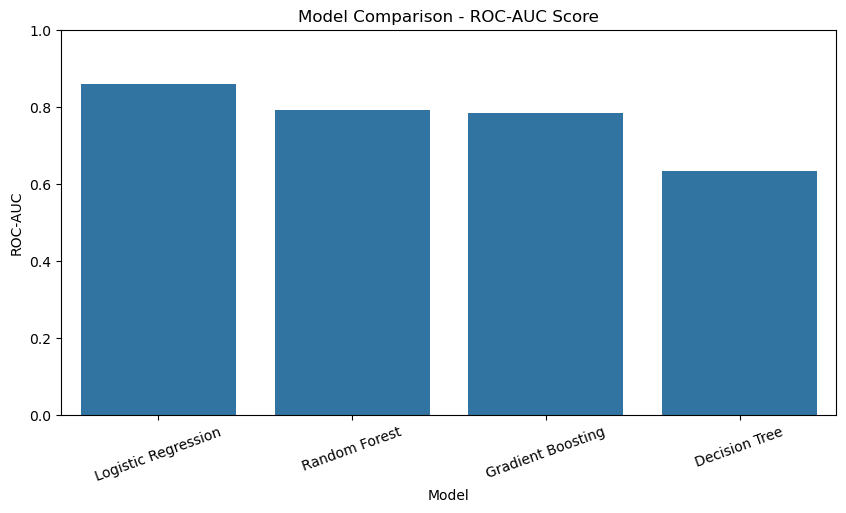

In [67]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_comparison,
    x='Model',
    y='ROC-AUC'
)

plt.title("Model Comparison - ROC-AUC Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.show()

15.4 Identify Best Performing Model

In [68]:
best_model_name = model_comparison.loc[0, 'Model']
best_roc_auc = model_comparison.loc[0, 'ROC-AUC']

print("Best Performing Model:", best_model_name)
print("Best ROC-AUC Score:", round(best_roc_auc, 4))

Best Performing Model: Logistic Regression
Best ROC-AUC Score: 0.8599


Step 16 – Hyperparameter Tuning

16.1 Import Required Library

In [69]:
from sklearn.model_selection import RandomizedSearchCV

16.2 Select Best Model

In [70]:
best_model_name = model_comparison.loc[0, 'Model']

print("Selected Model:", best_model_name)

Selected Model: Logistic Regression


16.3 Define Hyperparameters

In [71]:
if best_model_name == 'Logistic Regression':
    base_model = LogisticRegression(
        max_iter=500,
        random_state=42
    )
    param_grid = {
        'C': [0.01, 0.1, 1, 10],
        'class_weight': ['balanced', None]
    }
    X_tune = X_train_scaled

elif best_model_name == 'Random Forest':
    base_model = RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    )
    param_grid = {
        'n_estimators': [50, 100],
        'max_depth': [5, 10, 15],
        'class_weight': ['balanced', None]
    }
    X_tune = X_train

elif best_model_name == 'Decision Tree':
    base_model = DecisionTreeClassifier(random_state=42)
    param_grid = {
        'max_depth': [5, 10, 15, None],
        'min_samples_split': [2, 5, 10],
        'class_weight': ['balanced', None]
    }
    X_tune = X_train

else:
    base_model = GradientBoostingClassifier(random_state=42)
    param_grid = {
        'n_estimators': [30, 50],
        'learning_rate': [0.05, 0.1],
        'max_depth': [2, 3]
    }
    X_tune = X_train

print("Hyperparameters defined successfully!")

Hyperparameters defined successfully!


16.4 Perform Hyperparameter Tuning

In [72]:
random_search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_grid,
    n_iter=3,
    scoring='roc_auc',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_tune, y_train)

print("Hyperparameter Tuning Completed!")

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Hyperparameter Tuning Completed!


16.5 Display Best Parameters

In [73]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(random_search.best_score_)

Best Parameters:
{'class_weight': None, 'C': 0.01}

Best Cross-Validation ROC-AUC:
0.8589377723314403


16.6 Store Tuned Model

In [74]:
best_model = random_search.best_estimator_

print("Optimized Model:", best_model)

Optimized Model: LogisticRegression(C=0.01, max_iter=500, random_state=42)


Step 17 – Final Model Selection and Production Suitability

17.1 Make Predictions Using Tuned Model

In [75]:
if best_model_name == 'Logistic Regression':
    X_final_test = X_test_scaled
else:
    X_final_test = X_test

y_pred_final = best_model.predict(X_final_test)
y_prob_final = best_model.predict_proba(X_final_test)[:, 1]

print("Final Model Predictions Generated Successfully!")

Final Model Predictions Generated Successfully!


17.2 Evaluate Final Model

In [76]:
print("Final Model:", best_model_name)

print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(y_test, y_pred_final))
print("Recall:", recall_score(y_test, y_pred_final))
print("F1 Score:", f1_score(y_test, y_pred_final))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_final))

Final Model: Logistic Regression
Accuracy: 0.91325
Precision: 0.6821192052980133
Recall: 0.2562189054726368
F1 Score: 0.37251356238698013
ROC-AUC: 0.859864953996001


17.3 Display Classification Report

In [77]:
print(classification_report(y_test, y_pred_final))

              precision    recall  f1-score   support

           0       0.92      0.99      0.95     35980
           1       0.68      0.26      0.37      4020

    accuracy                           0.91     40000
   macro avg       0.80      0.62      0.66     40000
weighted avg       0.90      0.91      0.90     40000



17.4 Plot Confusion Matrix

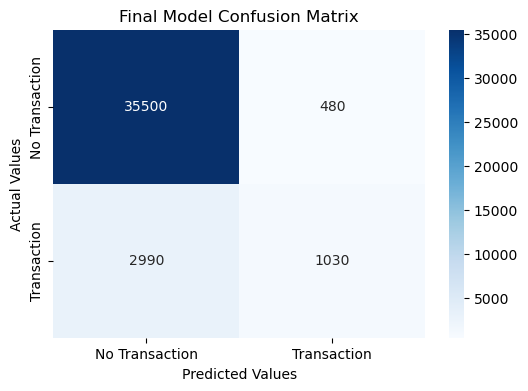

In [78]:
cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Transaction', 'Transaction'],
    yticklabels=['No Transaction', 'Transaction']
)

plt.title("Final Model Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

17.5 Save Final Model

In [79]:
import joblib

model_path = r"E:\Customer_Transaction_Prediction\final_customer_transaction_model.pkl"

joblib.dump(best_model, model_path)

print("Final Model Saved Successfully!")
print("Saved Location:", model_path)

Final Model Saved Successfully!
Saved Location: E:\Customer_Transaction_Prediction\final_customer_transaction_model.pkl


17.6 Save Scaler (Only for Logistic Regression)

In [80]:
if best_model_name == 'Logistic Regression':
    scaler_path = r"E:\Customer_Transaction_Prediction\customer_transaction_scaler.pkl"
    joblib.dump(scaler, scaler_path)
    print("Scaler Saved Successfully!")

Scaler Saved Successfully!


Step 18 – Challenges Faced Report

18.1 Challenges and Solutions

In [81]:
challenges_report = pd.DataFrame({
    'Challenges': [
        'Anonymized Feature Names',
        'Large Dataset',
        'Class Imbalance',
        'Model Training Time',
        'Feature Scaling',
        'Model Selection'
    ],
    'Solutions': [
        'Used statistical analysis and machine learning techniques without assuming feature meanings.',
        'Used efficient Pandas operations and an 80:20 train-test split.',
        'Used class_weight balancing in suitable classification models.',
        'Reduced Gradient Boosting estimators and tree depth to improve training time.',
        'Applied StandardScaler for Logistic Regression.',
        'Compared multiple models using Accuracy, Precision, Recall, F1-score and ROC-AUC.'
    ]
})

challenges_report

,Challenges,Solutions
0,Anonymized Feature Names,Used statistical analysis and machine learning...
1,Large Dataset,Used efficient Pandas operations and an 80:20 ...
2,Class Imbalance,Used class_weight balancing in suitable classi...
3,Model Training Time,Reduced Gradient Boosting estimators and tree ...
4,Feature Scaling,Applied StandardScaler for Logistic Regression.
5,Model Selection,"Compared multiple models using Accuracy, Preci..."


18.2 Project Conclusion

In [82]:
print("""
PROJECT CONCLUSION

The Customer Transaction Prediction project was developed
using machine learning classification techniques.

The dataset contained 200 anonymized numerical features,
a customer identifier and a target variable.

Data preprocessing and feature selection were performed
before training multiple classification models.

Logistic Regression, Random Forest, Decision Tree and
Gradient Boosting were considered for model comparison.

The models were evaluated using Accuracy, Precision,
Recall, F1-score and ROC-AUC.

Hyperparameter tuning was performed on the selected model
to improve its performance.

The final model was evaluated and saved for future use.

This project demonstrates how machine learning can help
banks identify customers who are likely to make future
transactions and support data-driven decision-making.
""")


PROJECT CONCLUSION

The Customer Transaction Prediction project was developed
using machine learning classification techniques.

The dataset contained 200 anonymized numerical features,
a customer identifier and a target variable.

Data preprocessing and feature selection were performed
before training multiple classification models.

Logistic Regression, Random Forest, Decision Tree and
Gradient Boosting were considered for model comparison.

The models were evaluated using Accuracy, Precision,
Recall, F1-score and ROC-AUC.

Hyperparameter tuning was performed on the selected model
to improve its performance.

The final model was evaluated and saved for future use.

This project demonstrates how machine learning can help
banks identify customers who are likely to make future
transactions and support data-driven decision-making.

